<a href="https://colab.research.google.com/github/shaikhshafaulla/PDS-PBL-3/blob/main/PDS_PBL_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name:** Shafaulla Shaikh  
**Enrollment No.:** 240090107199  
**Course:** B.E. Computer Engineering  
**Subject:** Python for Data Science  
**PBL Activity:** PBL 3  
**Project Title:** AI-Based Customer Churn Prediction  
**Dataset:** Customer Churn Dataset  

**Description:**  
In this step, the customer churn dataset is uploaded and loaded using Pandas. The first five records, dataset shape, and column names are displayed to understand the structure of the dataset.

##Step 1: Load Customer Churn Dataset and Explore Dataset Structure

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload dataset
uploaded = files.upload()

# Get uploaded file name automatically
file_name = next(iter(uploaded))

# Load dataset
df = pd.read_csv(file_name)

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

Saving customer_churn_dataset.csv to customer_churn_dataset.csv
First 5 rows of the dataset:


,Customer_ID,Age,Monthly_Usage,Monthly_Charges,Support_Calls,Contract_Type,Tenure_Months,Churn
0,C001,34,15,65,1,Two-Year,40,No
1,C002,45,10,50,0,Two-Year,55,No
2,C003,23,28,85,6,Month-to-Month,3,Yes
3,C004,31,20,70,2,One-Year,18,No
4,C005,52,8,45,1,Two-Year,60,No



Dataset Shape: (25, 8)

Column Names:
['Customer_ID', 'Age', 'Monthly_Usage', 'Monthly_Charges', 'Support_Calls', 'Contract_Type', 'Tenure_Months', 'Churn']


## Step 2: Data Cleaning
In this step, we check the dataset for missing values and duplicate records to ensure data quality.

In [ ]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Check for duplicate records
print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
Customer_ID        0
Age                0
Monthly_Usage      0
Monthly_Charges    0
Support_Calls      0
Contract_Type      0
Tenure_Months      0
Churn              0
dtype: int64

Number of Duplicate Records:
0


##Step 3: Data Preprocessing
Categorical values are converted into numerical values so that they can be used by the machine learning model.

In [ ]:
# Convert Contract Type into numerical values
df["Contract_Type_Code"] = df["Contract_Type"].map({
    "Month-to-Month": 0,
    "One-Year": 1,
    "Two-Year": 2
})

# Convert Churn into numerical values
df["Churn_Code"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Display the converted data
display(df[[
    "Contract_Type",
    "Contract_Type_Code",
    "Churn",
    "Churn_Code"
]].head())

,Contract_Type,Contract_Type_Code,Churn,Churn_Code
0,Two-Year,2,No,0
1,Two-Year,2,No,0
2,Month-to-Month,0,Yes,1
3,One-Year,1,No,0
4,Two-Year,2,No,0


##Step 4: Data Analysis
In this step, we analyze customer churn and compare important customer characteristics such as support calls and monthly charges.

In [ ]:
# Churn count
print("Customer Churn Count:")
print(df["Churn"].value_counts())

# Average values based on churn
print("\nAverage values by Churn:")
print(
    df.groupby("Churn")[[
        "Monthly_Usage",
        "Monthly_Charges",
        "Support_Calls",
        "Tenure_Months"
    ]].mean().round(2)
)

Customer Churn Count:
Churn
No     16
Yes     9
Name: count, dtype: int64

Average values by Churn:
       Monthly_Usage  Monthly_Charges  Support_Calls  Tenure_Months
Churn                                                              
No             13.75             57.0           1.12           38.0
Yes            29.00             86.0           6.78            3.0


##Step 5: Data Visualization
Visualizations are used to understand the relationship between customer churn, support calls, and monthly charges.

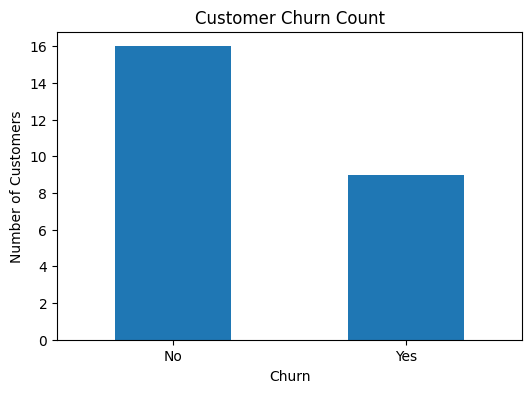

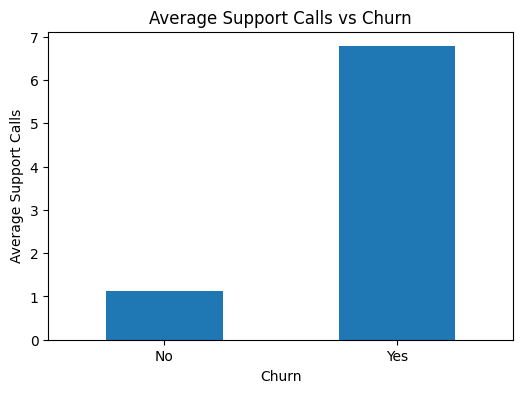

In [ ]:
# 1. Churn Count
plt.figure(figsize=(6,4))
df["Churn"].value_counts().plot(kind="bar")
plt.title("Customer Churn Count")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()


# 2. Average Support Calls vs Churn
avg_calls = df.groupby("Churn")["Support_Calls"].mean()

plt.figure(figsize=(6,4))
avg_calls.plot(kind="bar")
plt.title("Average Support Calls vs Churn")
plt.xlabel("Churn")
plt.ylabel("Average Support Calls")
plt.xticks(rotation=0)
plt.show()

##Step 6: Customer Churn Prediction using Logistic Regression
Logistic Regression is used to predict whether a customer will churn or not based on customer-related features.

In [ ]:
# Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Select features
features = [
    "Age",
    "Monthly_Usage",
    "Monthly_Charges",
    "Support_Calls",
    "Contract_Type_Code",
    "Tenure_Months"
]

# Input features and target
X = df[features]
y = df["Churn_Code"]

# Split data into training and testing sets
# Stratify keeps both Churn classes represented in the test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Machine Learning models
logistic_model = LogisticRegression(max_iter=1000)

decision_tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Logistic Regression
logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)
logistic_accuracy = accuracy_score(y_test, logistic_pred)

# Train Decision Tree
decision_tree_model.fit(X_train, y_train)
decision_tree_pred = decision_tree_model.predict(X_test)
decision_tree_accuracy = accuracy_score(y_test, decision_tree_pred)

# Train Random Forest
random_forest_model.fit(X_train, y_train)
random_forest_pred = random_forest_model.predict(X_test)
random_forest_accuracy = accuracy_score(y_test, random_forest_pred)

# Display results
print("Machine Learning Algorithm Comparison")
print("=" * 45)
print("Training Records:", len(X_train))
print("Testing Records :", len(X_test))
print()

print(f"Logistic Regression : {logistic_accuracy * 100:.2f}%")
print(f"Decision Tree       : {decision_tree_accuracy * 100:.2f}%")
print(f"Random Forest       : {random_forest_accuracy * 100:.2f}%")

Machine Learning Algorithm Comparison
Training Records: 20
Testing Records : 5

Logistic Regression : 100.00%
Decision Tree       : 100.00%
Random Forest       : 100.00%


##Step 7: Machine Learning Algorithm Comparison
Logistic Regression, Decision Tree, and Random Forest are compared to evaluate their performance for customer churn prediction.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Decision Tree
decision_tree.fit(X_train, y_train)
dt_pred = decision_tree.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

# Train Random Forest
random_forest.fit(X_train, y_train)
rf_pred = random_forest.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

# Display comparison
print("Machine Learning Algorithm Comparison")
print("-------------------------------------")
print(f"Logistic Regression : {accuracy * 100:.2f}%")
print(f"Decision Tree       : {dt_accuracy * 100:.2f}%")
print(f"Random Forest       : {rf_accuracy * 100:.2f}%")

Machine Learning Algorithm Comparison
-------------------------------------
Logistic Regression : 100.00%
Decision Tree       : 100.00%
Random Forest       : 100.00%


##Step 8: Model Evaluation
The selected machine learning model is evaluated using a confusion matrix and classification report. These measures show the prediction performance of the model.

Final Selected Model: Logistic Regression
Accuracy: 100.0 %

Confusion Matrix:
[[3 0]
 [0 2]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       1.00      1.00      1.00         3
       Churn       1.00      1.00      1.00         2

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



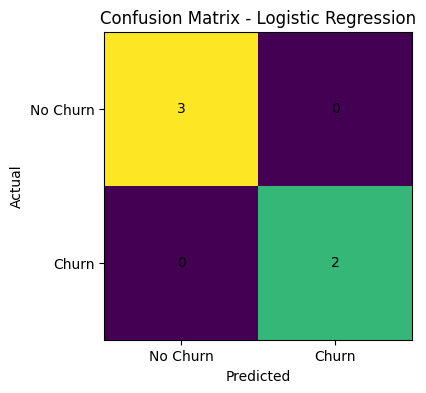

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# Store model results
model_results = {
    "Logistic Regression": (logistic_model, logistic_pred, logistic_accuracy),
    "Decision Tree": (decision_tree_model, decision_tree_pred, decision_tree_accuracy),
    "Random Forest": (random_forest_model, random_forest_pred, random_forest_accuracy)
}

# Select model with highest accuracy
best_name = max(
    model_results,
    key=lambda name: model_results[name][2]
)

best_model, best_pred, best_accuracy = model_results[best_name]

print("Final Selected Model:", best_name)
print("Accuracy:", round(best_accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Display Confusion Matrix
plt.figure(figsize=(5, 4))
plt.imshow(cm)

plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No Churn", "Churn"])
plt.yticks([0, 1], ["No Churn", "Churn"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()